Sara de los angeles Carmona Catalan

In [13]:
import random, math
import numpy as np
import matplotlib.pyplot as plt

random.seed(2026)
np.random.seed(2026)

In [14]:
n = 10_000
lam = 0.5
np_unif = np.random.uniform(1, 4, n)
np_exp  = np.random.exponential(scale=1/lam, size=n)   # scale = 2, NO 0.5
np_norm = np.random.normal(8, 1.5, n)

In [15]:
def resumen(nombre, x, mu_t, var_t):
    print(f"{nombre}: media={np.mean(x):.3f} (teórica {mu_t}), "
          f"var={np.var(x):.3f} (teórica {var_t})")

mis_unif = [uniforme(1, 4) for _ in range(n)]
mis_exp  = [exponencial(lam) for _ in range(n)]
mis_norm = [normal(8, 1.5) for _ in range(n)]

resumen("Uniforme (mía)",  mis_unif, 2.5, 0.75)
resumen("Uniforme (NumPy)", np_unif, 2.5, 0.75)
resumen("Exponencial (mía)",  mis_exp, 2, 4)
resumen("Exponencial (NumPy)", np_exp, 2, 4)
resumen("Normal (mía)",  mis_norm, 8, 2.25)
resumen("Normal (NumPy)", np_norm, 8, 2.25)

Uniforme (mía): media=2.485 (teórica 2.5), var=0.742 (teórica 0.75)
Uniforme (NumPy): media=2.505 (teórica 2.5), var=0.748 (teórica 0.75)
Exponencial (mía): media=2.004 (teórica 2), var=4.127 (teórica 4)
Exponencial (NumPy): media=1.998 (teórica 2), var=3.869 (teórica 4)
Normal (mía): media=7.995 (teórica 8), var=2.224 (teórica 2.25)
Normal (NumPy): media=8.003 (teórica 8), var=2.275 (teórica 2.25)


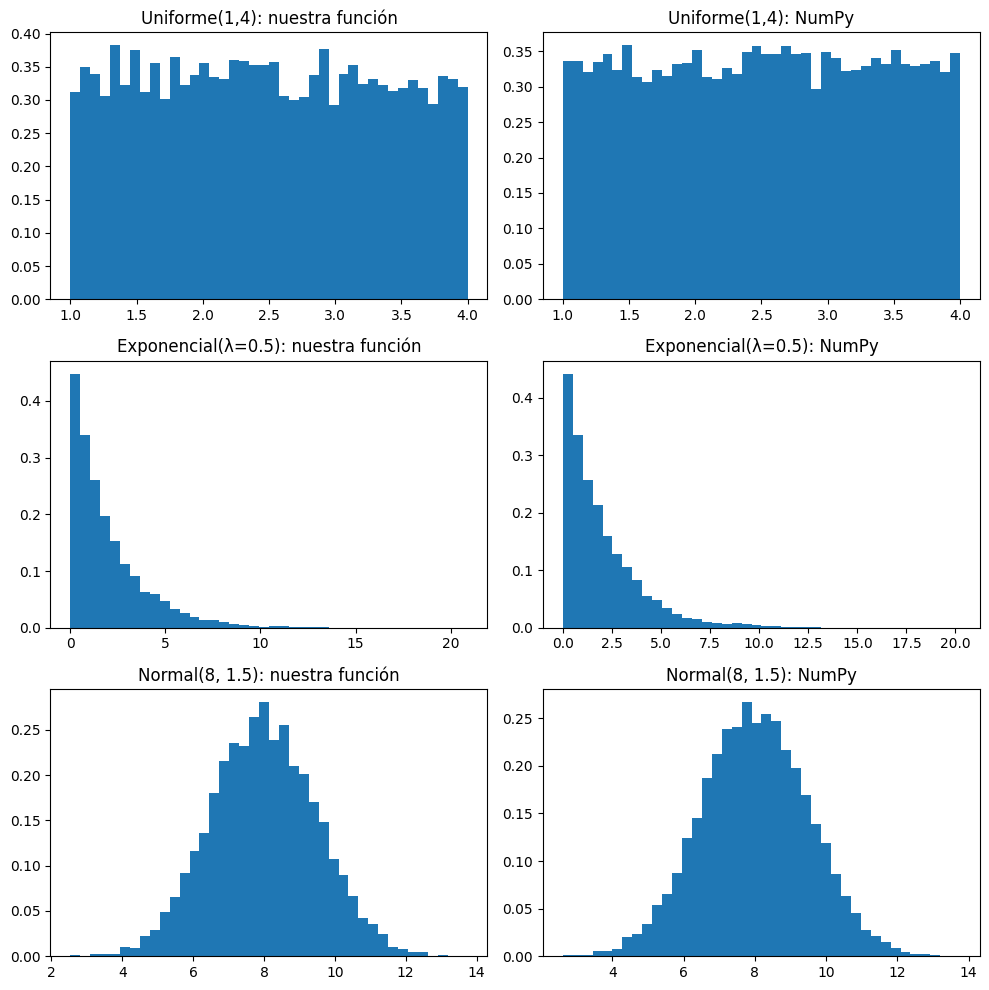

In [16]:
pares = [("Uniforme(1,4)", mis_unif, np_unif),
         ("Exponencial(λ=0.5)", mis_exp, np_exp),
         ("Normal(8, 1.5)", mis_norm, np_norm)]

fig, ejes = plt.subplots(3, 2, figsize=(10, 10))
for fila, (nombre, mia, npy) in zip(ejes, pares):
    fila[0].hist(mia, bins=40, density=True)
    fila[0].set_title(f"{nombre}: nuestra función")
    fila[1].hist(npy, bins=40, density=True)
    fila[1].set_title(f"{nombre}: NumPy")
plt.tight_layout()
plt.show()

In [17]:
def corrida(n_clientes=10):
    llegada = 0.0
    fin_servicio_anterior = 0.0
    esperas = []
    for _ in range(n_clientes):
        llegada += exponencial(1/2)              # media 2 min
        inicio = max(llegada, fin_servicio_anterior)
        esperas.append(inicio - llegada)
        servicio = uniforme(1, 4)                # cambiar a uniforme(1, 5) para la pregunta
        fin_servicio_anterior = inicio + servicio
    return sum(esperas) / n_clientes

espera_prom = sum(corrida() for _ in range(1000)) / 1000
print(f"Espera promedio: {espera_prom:.3f} min")

Espera promedio: 3.825 min


¿la espera promedio sube o baja? Sube la media del servicio, de 2.5 a 3 min. Las llegadas son una cada 2 min en promedio, así que la ventanilla pasa de una utilización de 2.5/2 = 125% a 3/2 = 150%. En ambos casos el servicio es más lento que las llegadas, así que se forma fila y crece conforme llegan clientes.
Sube la varianza del servicio, de 0.75 a 1.33. Más variabilidad significa más ocasiones en que un servicio largo hace esperar a los siguientes.